# 内容自适应软融合 P2P — Colab T4 小规模比较

比较 `p2p`、`soft_fixed`、`soft_adaptive`。不训练模型，不采用逐层或逐头权重。
真实图均使用共享 DDIM 反演，指标参考 **PnP Inversion / PIE-Bench**。

**VS Code：** 右上角 Select Kernel → Colab → New Colab Server，选择 **T4 GPU**。
本地 `gvproj` 用于开发和测试，Colab kernel 使用远端 Python；本地文件不会自动同步。
本笔记本也支持网页 Colab，但不依赖网页上传弹窗。本笔记本没有预填实验结果。
首次下载 SD 1.4、CLIP、DINO、LPIPS 较大；先下载，再开始约一小时的实验预算。
原文件保持原状；完整说明见 `ADAPTIVE_P2P_README.md`。

## 1. 项目与持久化目录

在 VS Code 本地资源管理器右键随附的 `adaptive_p2p_colab_bundle.zip` → **Upload to Colab**。
在 Colab 侧栏 **Contents** 查看实际远端路径；默认检查 `/content/adaptive_p2p_colab_bundle.zip`。
若上传路径不同，设置 `BUNDLE_PATH_OVERRIDE`；若已上传/克隆完整源码，设置 `PROJECT_DIR_OVERRIDE`。

推荐先执行命令 **Colab: Mount Google Drive to Server...** 并运行扩展插入的挂载单元格。
本程序不自行执行网页挂载。已挂载时默认保存到 Drive，否则使用 `/content/p2p_results`（临时）。
重启 kernel 后重跑本节。只有放在临时 `/content` 的文件才需在更换服务器后恢复。
可把代码 ZIP 一次上传到 Drive，然后设置
`BUNDLE_PATH_OVERRIDE="/content/drive/MyDrive/adaptive_p2p_colab_bundle.zip"`；
每台新服务器会从 Drive 自动解压到同一个 `/content/adaptive_p2p`，无需再次从电脑上传。
数据放在 Drive，结果直接写入 Drive 时，重新挂载并保持原路径即可，无需解压结果包。
新服务器仍需重新安装依赖；默认模型缓存位于临时磁盘，需重新下载。

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path
import shutil

src = Path("/content/adaptive_p2p_colab_bundle.zip")
dst = Path("/content/drive/MyDrive/adaptive_p2p_colab_bundle.zip")

assert dst.parent.is_dir(), "请先挂载 Google Drive"
assert src.is_file(), "请先通过 Upload to Colab 上传代码包"
if not dst.exists():
    shutil.copy2(src, dst)
print("Drive 代码包：", dst, "存在：", dst.is_file())

Drive 代码包： /content/drive/MyDrive/adaptive_p2p_colab_bundle.zip 存在： True


In [ ]:
import os, sys
from pathlib import Path
PROJECT_DIR_OVERRIDE = None
BUNDLE_PATH_OVERRIDE = "/content/drive/MyDrive/adaptive_p2p_colab_bundle.zip"
RESULTS_ROOT_OVERRIDE = "/content/drive/MyDrive/p2p_research"
REMOTE_ROOT = "/content" if sys.platform == "linux" and Path("/content").is_dir() else None
IN_COLAB = REMOTE_ROOT is not None
"""Standard-library bootstrap, embedded in the notebook before project imports.

Works with VS Code Colab extension, browser Colab and a local gvproj kernel.
No frontend-specific upload, download or authentication widgets are invoked.
"""
import hashlib
import os
import sys
import zipfile
from pathlib import Path, PureWindowsPath


def runtime_path(value, *, base=None):
    value = str(value)
    if os.name != "nt" and (PureWindowsPath(value).drive or "\\" in value):
        raise ValueError("Remote Linux cannot read a Windows path. Upload the file and use its /content/... path: " + value)
    path = Path(value).expanduser()
    return ((Path(base) / path) if base is not None and not path.is_absolute() else path).resolve()


def extract_runtime_bundle(bundle, destination):
    bundle, destination = Path(bundle), Path(destination).resolve()
    checksum = hashlib.sha256(bundle.read_bytes()).hexdigest()
    marker = destination / ".uploaded_bundle_sha256"
    if marker.exists() and marker.read_text().strip() == checksum:
        return destination
    if any(name in sys.modules for name in ("adaptive_p2p", "evaluate_adaptive_p2p")):
        raise RuntimeError("New project bundle detected. Restart Kernel before extracting updated code.")
    with zipfile.ZipFile(bundle) as archive:
        # Check the complete archive before extracting anything.
        for member in archive.infolist():
            name = member.filename
            path = destination / name
            if PureWindowsPath(name).drive or "\\" in name or not path.resolve().is_relative_to(destination):
                raise ValueError("Unsafe archive member: " + name)
            if (member.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError("Archive symlinks are not supported: " + name)
        if "adaptive_p2p.py" not in archive.namelist():
            raise ValueError("Use the generated flat adaptive_p2p_colab_bundle.zip.")
        destination.mkdir(parents=True, exist_ok=True)
        archive.extractall(destination)
    marker.write_text(checksum, encoding="utf-8")
    return destination


def setup_runtime(project_dir=None, bundle_path=None, remote_root=None, results_root=None):
    cwd = Path.cwd()
    remote = runtime_path(remote_root) if remote_root else None
    if project_dir:
        project = runtime_path(project_dir, base=remote or cwd)
    elif remote:
        project = remote / "adaptive_p2p"
    else:
        candidates = [p for p in (cwd, *cwd.parents) if (p / "adaptive_p2p.py").is_file()]
        if not candidates:
            raise FileNotFoundError("Set PROJECT_DIR_OVERRIDE to the project directory visible to this kernel.")
        project = candidates[0]
    bundle = runtime_path(bundle_path, base=remote or cwd) if bundle_path else (
        remote / "adaptive_p2p_colab_bundle.zip" if remote else None)
    # Explicit project override uses uploaded source files; explicit bundle overrides it.
    if bundle and bundle.is_file() and (not project_dir or bundle_path):
        extract_runtime_bundle(bundle, project)
    required = ("adaptive_p2p.py", "evaluate_adaptive_p2p.py", "requirements-adaptive.txt",
                "prompt-to-prompt/seq_aligner.py", "vendor/reference_manifest.json")
    missing = [name for name in required if not (project / name).is_file()]
    if missing:
        visible = sorted(p.name for p in remote.iterdir()) if remote and remote.is_dir() else []
        raise FileNotFoundError(
            f"Project not available to kernel at {project}. Missing: {missing}. "
            f"Upload adaptive_p2p_colab_bundle.zip using VS Code 'Upload to Colab', then set BUNDLE_PATH_OVERRIDE "
            f"to the uploaded remote path if needed. Remote files: {visible}")
    drive = remote / "drive" / "MyDrive" if remote else None
    if results_root:
        results = runtime_path(results_root, base=remote or project)
    elif drive is not None and drive.is_dir():
        results = drive / "p2p_research"
    else:
        results = (remote / "p2p_results") if remote else (project / "results")
    if remote and "drive" in results.parts and drive is not None and not drive.is_dir():
        raise FileNotFoundError("Drive is not mounted. Use 'Colab: Mount Google Drive to Server...' first.")
    results.mkdir(parents=True, exist_ok=True)
    os.chdir(project)
    if str(project) not in sys.path:
        sys.path.insert(0, str(project))
    os.environ.setdefault("HF_HOME", str(remote / "p2p_model_cache" if remote else project / ".model_cache"))
    os.environ.setdefault("TORCH_HOME", str(Path(os.environ["HF_HOME"]) / "torch"))
    os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
    print("Kernel Python:", sys.executable)
    print("Project:", project)
    print("Results root:", results)
    if remote and (drive is None or not results.is_relative_to(drive)):
        print("Remote temporary storage: download the checkpoint ZIP before deleting/replacing the Colab server.")
    return project, results


os.environ["HF_HOME"] = "/content/drive/MyDrive/p2p_model_cache"
os.environ["TORCH_HOME"] = "/content/drive/MyDrive/p2p_model_cache/torch"

PROJECT_DIR, RESULTS_ROOT = setup_runtime(
    PROJECT_DIR_OVERRIDE, BUNDLE_PATH_OVERRIDE, REMOTE_ROOT, RESULTS_ROOT_OVERRIDE)

Kernel Python: /usr/bin/python3
Project: /content/adaptive_p2p
Results root: /content/drive/MyDrive/p2p_research


## 2. 安装固定研究依赖

Colab 保留自带的匹配 PyTorch/torchvision/CUDA，不安装本地 CPU wheel。
本研究依赖使用 **Python 3.12**；Python 3.13 不兼容固定的 NumPy 1.26.4。
若当前为 3.13，请先切换 Python 3.12 运行时。网页 Colab 可在
Runtime → Change runtime type → Runtime Version 选择 `2026.07`（Python 3.12.13）。
若 VS Code 扩展未提供版本选项，可先使用网页 Colab 的上述入口运行；不要替换系统 Python。
版本列表见 https://research.google.com/colaboratory/runtime-version-faq.html 。
安装输出实时显示，并保存在结果根目录 `setup_logs/`，便于定位具体 pip 错误。
**首次安装完成后，点击 VS Code notebook 工具栏 Restart Kernel，再从第 1 节重新运行，跳过安装单元格。**
本地请选择 `gvproj` kernel，按 README 安装 CPU PyTorch 后运行测试。

In [6]:
import subprocess, sys
from datetime import datetime, timezone
print("Python:", sys.version, "Executable:", sys.executable, flush=True)
if sys.version_info[:2] != (3, 12):
    raise RuntimeError("本项目固定依赖请使用 Python 3.12；当前为 " + sys.version.split()[0]
                       + "。请切换 Colab Runtime Version 后重跑第一节，不要在当前会话替换系统 Python。")
log_dir = RESULTS_ROOT / "setup_logs"
log_dir.mkdir(parents=True, exist_ok=True)
log_path = log_dir / (datetime.now(timezone.utc).strftime("pip-install-%Y%m%dT%H%M%S%fZ") + ".log")
command = [sys.executable, "-m", "pip", "install", "-r", str(PROJECT_DIR / "requirements-adaptive.txt")]
with log_path.open("w", encoding="utf-8") as log:
    log.write("Python: " + sys.version + "\nCommand: " + repr(command) + "\n")
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, encoding="utf-8", errors="replace", bufsize=1) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        returncode = process.wait()
print("完整安装日志:", log_path)
if returncode:
    raise RuntimeError(f"pip 安装失败（exit={returncode}）；请查看上方具体 ERROR 或日志 {log_path}")
print("首次安装后请重启 Python 会话，重新运行第 1 节，再继续第 3 节。")

Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0] Executable: /usr/bin/python3
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 5.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 8.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 110.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 128.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.9/374.9 kB 41.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 561.5/561.5 kB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 869.5/869.5 kB 70.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 125.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 162.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 152.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 3. 环境检查与离线逻辑测试

测试使用小型随机 UNet 和固定 tokenizer，不下载 SD 权重，也不证明编辑质量。
原 P2P notebook 仅抽取控制器定义作张量对照，不执行其中的模型下载或演示。

In [2]:
import json, subprocess
import torch, torchvision, diffusers, transformers
from adaptive_p2p import EditConfig, environment_snapshot, save_json
from evaluate_adaptive_p2p import prefetch_assets, run_experiment, generated_samples, verify_pretrained_metrics

assert diffusers.__version__ == "0.35.1", "依赖版本不符，请安装后重启"
print(json.dumps(environment_snapshot(), indent=2, ensure_ascii=False))
RUN_LOGIC_TESTS = True
if RUN_LOGIC_TESTS:
    subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "--disable-warnings"], check=True)

{
  "python": "3.12.13",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.35",
  "packages": {
    "torch": "2.11.0+cu128",
    "torchvision": "0.26.0+cu128",
    "diffusers": "0.35.1",
    "transformers": "4.44.2",
    "accelerate": "1.10.1",
    "huggingface-hub": "0.34.4",
    "torchmetrics": "1.4.3",
    "numpy": "1.26.4",
    "Pillow": "10.4.0",
    "pandas": "2.2.3"
  },
  "cuda": "12.8",
  "gpu": "Tesla T4"
}


## 3b. PIE-Bench 获取与重复性检查（不计入 GPU 实验预算）

官方需要先通过 https://forms.gle/hVMkTABb4uvZVjme9 获取下载地址；程序不自动提交申请。
将 `USE_PIE_BENCH=True`，填写授权下载链接或 Drive 中已有 ZIP 路径。
支持 HTTPS ZIP 和 Google Drive 文件分享链接，不支持文件夹链接；有权限/配额问题时请手动下载到 Drive。
数据已存在时复用并重新检查，不重复下载；Google Drive 的部分下载可尝试续传，普通 HTTPS 中断后重新下载。
输出 dataset_audit.json：文件哈希、损坏/缺失文件、解码像素完全相同的图像、重复编辑任务。
重复源图可能对应不同任务，因此只报告不删图；抽样后检查开发/测试图像重叠，若存在则停止，不按结果换图。
这不是近似图像检索，也不是重新跑两次 GPU 实验的数值复现测试。
启用真实图时第四节自动使用独立的 pie_small_vscode_v1 目录，不复用生成图实验目录。

In [ ]:
from scripts.pie_dataset import prepare_pie_dataset
USE_PIE_BENCH = False
PIE_DOWNLOAD_URL = None  # 官方申请后获得的 HTTPS ZIP / Google Drive 文件链接
PIE_ARCHIVE_PATH = "/content/drive/MyDrive/PIE-Bench.zip"
PIE_DESTINATION = "/content/drive/MyDrive/PIE-Bench"
PIE_EXPECTED_SHA256 = None  # 若提供方给出校验值，可填写；本地生成哈希不代表官方认证
PIE_DATA_ROOT = None
if USE_PIE_BENCH:
    if not Path("/content/drive/MyDrive").is_dir():
        raise RuntimeError("请先挂载 Google Drive。")
    PIE_DATA_ROOT = prepare_pie_dataset(PIE_DESTINATION, PIE_ARCHIVE_PATH,
                                       PIE_DOWNLOAD_URL, PIE_EXPECTED_SHA256)
    audit = json.loads((PIE_DATA_ROOT / "dataset_audit.json").read_text())
    print(json.dumps({k: v for k, v in audit.items() if k != "files"}, ensure_ascii=False, indent=2))
else:
    print("PIE-Bench 未启用；第四节继续运行生成图。")

## 4. 数据与运行配置

尚无真实图时，保留 `DATA_ROOT=None`，四组生成图可以独立运行。
真实图需先从 [PIE-Bench 官方入口](https://github.com/cure-lab/PnPInversion#benchmark-download)
获取数据；`DATA_ROOT` 下必须含 `mapping_file.json` 与 `annotation_images/`。

每类一张开发图、最多三张测试图，类别为对象/姿态/颜色/材质。固定筛选规则和 seed=2026；
不符合词替换要求的样本会记录排除原因，不能根据编辑效果换图。官方掩码仅供评测。

**保持 OUTPUT_DIR 不变可续跑；修改代码、模型、依赖或数据时使用新目录。**
生成图实验和加入真实数据后的完整实验也应使用不同目录。

In [3]:
DATA_ROOT = str(PIE_DATA_ROOT) if globals().get("PIE_DATA_ROOT") else None
# DATA_ROOT = "/content/PIE-Bench"  # 通过扩展上传并解压后的远端目录
# DATA_ROOT = "/content/drive/MyDrive/PIE-Bench"  # 已挂载 Drive
if DATA_ROOT is not None:
    DATA_ROOT = str(runtime_path(DATA_ROOT, base=PROJECT_DIR))
OUTPUT_DIR = RESULTS_ROOT / ("synthetic_vscode_v1" if DATA_ROOT is None else "pie_small_vscode_v1")
BUDGET_SECONDS = 3600

assert torch.cuda.is_available(), "完整实验需要 GPU：请在 Colab 选择 T4。本地仅运行前面的测试。"
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM GiB:", torch.cuda.get_device_properties(0).total_memory / 2**30)
if DATA_ROOT is not None:
    assert (Path(DATA_ROOT) / "mapping_file.json").exists()
    assert (Path(DATA_ROOT) / "annotation_images").is_dir()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
config = EditConfig(output_dir=str(OUTPUT_DIR))  # 512px, 30 DDIM steps, CFG=7.5, FP16
print("Results:", OUTPUT_DIR)
for sample in generated_samples():
    print(sample["id"], sample["case"]["source_prompt"], "->", sample["case"]["target_prompt"])

GPU: Tesla T4
VRAM GiB: 14.56317138671875
Results: /content/drive/MyDrive/p2p_research/synthetic_vscode_v1
generated_6 a photo of a red car parked on a street -> a photo of a blue car parked on a street
generated_7 a photo of a wooden bowl on a table -> a photo of a glass bowl on a table
generated_1 a photo of a bicycle beside a brick wall -> a photo of a motorcycle beside a brick wall
generated_5 a photo of a sitting dog in a grassy park -> a photo of a standing dog in a grassy park


## 5. 预下载（不计入实验预算）

包括 SD 1.4、CLIP ViT-L/14、DINO ViT-B/8、LPIPS SqueezeNet。指标模型在 CPU 预加载后释放。
如果模型需要认证，使用 `huggingface_hub.login()` 的交互输入或远端环境变量 `HF_TOKEN`。
不依赖网页 Colab secrets，不要把明文 token 保存进 notebook。
下载失败时先解决网络/访问问题；不会自动切换模型或指标。

In [4]:
config = prefetch_assets(config)
print("Pinned SD revision:", config.model_revision)
# 在CPU核对真实指标权重的官方实现一致性；不是编辑效果实验。
CHECK_METRIC_PARITY = True
if CHECK_METRIC_PARITY:
    save_json(OUTPUT_DIR / "pretrained_metric_parity.json", verify_pretrained_metrics("cpu"))
save_json(OUTPUT_DIR / "prefetch_environment.json", environment_snapshot())
(OUTPUT_DIR / "pip-freeze.txt").write_text(
    subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

scheduler_config-checkpoint.json:   0%|          | 0.00/209 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

... (22 outputs left out)

100%|██████████| 327M/327M [00:01<00:00, 314MB/s] 


Pinned SD revision: 133a221b8aa7292a167afc5127cb63fb5005638b
Validating pretrained metric family: pixels
Validating pretrained metric family: clip
Validating pretrained metric family: lpips
Validating pretrained metric family: structure


Using cache found in /content/p2p_model_cache/torch/hub/facebookresearch_dino_7c446df5b9f45747937fb0d72314eb9f7b66930a


14061

## 6. 运行或断点续跑

有真实数据时：开发集原 P2P τ=0.4/0.6/0.8 → CLIP Edit/背景 LPIPS 选 τ →
固定软融合和自适应开发消融 → 四组生成图 → 按剩余预算选择12/8/4/0张真实测试图 → 指标和图表。

未修改词采用全程注入，self-attention 前40%步保持原策略，三方法均关闭 LocalBlend。
为评测预留至少10分钟；计时是操作间的软预算，单次操作或断线可能带来估计误差。
一小时内是否能完成12张真实图取决于实际吞吐；`coverage.json` 会公开未完成情况。

In [7]:
result_dir = run_experiment(config, data_root=DATA_ROOT, limit_seconds=BUDGET_SECONDS)
print("Finished/checkpointed:", result_dir or OUTPUT_DIR)
for filename in ("status.json", "selected_tau.json", "test_selection.json", "coverage.json"):
    path = OUTPUT_DIR / filename
    if path.exists():
        print(filename, path.read_text(encoding="utf-8"))

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Using cache found in /content/drive/MyDrive/p2p_model_cache/torch/hub/facebookresearch_dino_7c446df5b9f45747937fb0d72314eb9f7b66930a


Finished/checkpointed: /content/drive/MyDrive/p2p_research/synthetic_vscode_v1
status.json {
  "status": "finished_available_budget",
  "spent_seconds": 182.1339525449996,
  "selected_test_samples": 0,
  "limit_seconds": 3600,
  "note": "Inspect coverage.json for missing methods/metrics; no claim of improvement."
}
selected_tau.json {
  "tau": 0.6,
  "source": "preregistered_generated_only_default; no PIE data"
}
test_selection.json {
  "sample_ids": [],
  "estimated_seconds_per_case": 41.66857074420013,
  "remaining_at_selection": 3431.540598888,
  "reason": "runtime only; before inspecting test outputs"
}
coverage.json [
  {
    "split": "generated",
    "planned_samples": 4,
    "samples_with_all_methods": 4,
    "paired_valid_n_per_metric": {
      "structure_distance": 4,
      "psnr_bg": 0,
      "lpips_bg": 0,
      "mse_bg": 0,
      "ssim_bg": 0,
      "clip_whole": 4,
      "clip_edit": 0
    },
    "missing_ids": []
  },
  {
    "split": "test",
    "planned_samples": 0,
   

## 7. 定量结果与资源

`summary.csv` 的 mean 是原始值、display_mean 是论文样式缩放值；CLIPScore 不重复乘100。
背景区域按官方置零方式计算，DINO 保留官方0–255 float输入；不与论文不同配置的完整数值直接比较。
生成图没有人工掩码，只报告结构距离与 CLIP Whole。开发图不进入测试均值。
bootstrap 是自适应减去对照的配对差值：CLIP正值好，距离负值好；小样本区间可能退化。

In [8]:
import pandas as pd
from IPython.display import display, Markdown, Image as DisplayImage
for filename in ("summary.csv", "paired_bootstrap.csv"):
    path = OUTPUT_DIR / filename
    if path.exists() and path.stat().st_size > 1:
        display(Markdown("**" + filename + "**"))
        display(pd.read_csv(path))
criteria = OUTPUT_DIR / "exploratory_criteria.json"
if criteria.exists():
    print(criteria.read_text(encoding="utf-8"))
registry_path = OUTPUT_DIR / "registry.json"
if registry_path.exists():
    registry = json.loads(registry_path.read_text())
    timings = [{"id": r["sample_id"], "method": r["result"]["method"],
                "tau": r["result"]["config"]["tau"],
                "edit_seconds": r["result"]["edit_seconds"],
                "peak_memory_mib": r["result"]["peak_memory_mib"]} for r in registry["records"]]
    display(pd.DataFrame(timings))

**summary.csv**

,split,category,method,metric,mean,n,display_multiplier,display_mean
0,generated,all,p2p,structure_distance,0.029757,4,1000,29.757313
1,generated,all,soft_adaptive,structure_distance,0.032682,4,1000,32.682232
2,generated,all,soft_fixed,structure_distance,0.032714,4,1000,32.714466
3,generated,1,p2p,structure_distance,0.052559,1,1000,52.559134
4,generated,1,soft_adaptive,structure_distance,0.062334,1,1000,62.334325
...,...,...,...,...,...,...,...,...
70,generated,6,soft_adaptive,peak_memory_mib,2997.244141,1,1,2997.244141
71,generated,6,soft_fixed,peak_memory_mib,2997.244141,1,1,2997.244141
72,generated,7,p2p,peak_memory_mib,2997.244141,1,1,2997.244141
73,generated,7,soft_adaptive,peak_memory_mib,2997.244141,1,1,2997.244141


**paired_bootstrap.csv**

,metric,comparator,n,delta,ci_low,ci_high
0,structure_distance,p2p,0,NaN,NaN,NaN
1,structure_distance,soft_fixed,0,NaN,NaN,NaN
2,psnr_bg,p2p,0,NaN,NaN,NaN
3,psnr_bg,soft_fixed,0,NaN,NaN,NaN
4,lpips_bg,p2p,0,NaN,NaN,NaN
5,lpips_bg,soft_fixed,0,NaN,NaN,NaN
6,mse_bg,p2p,0,NaN,NaN,NaN
7,mse_bg,soft_fixed,0,NaN,NaN,NaN
8,ssim_bg,p2p,0,NaN,NaN,NaN
9,ssim_bg,soft_fixed,0,NaN,NaN,NaN


[
  {
    "comparator": "p2p",
    "status": "insufficient_data"
  },
  {
    "comparator": "soft_fixed",
    "status": "insufficient_data"
  }
]


,id,method,tau,edit_seconds,peak_memory_mib
0,generated_6,p2p,0.6,9.270410,2997.244141
1,generated_6,soft_fixed,0.6,8.676189,2997.244141
2,generated_6,soft_adaptive,0.6,8.806662,2997.244141
3,generated_7,p2p,0.6,9.020368,2997.244141
4,generated_7,soft_fixed,0.6,9.098959,2997.244141
5,generated_7,soft_adaptive,0.6,9.187096,2997.244141
6,generated_1,p2p,0.6,9.408653,2997.244141
7,generated_1,soft_fixed,0.6,9.496668,2997.244141
8,generated_1,soft_adaptive,0.6,9.723981,2997.244141
9,generated_5,p2p,0.6,10.019202,2997.244141


## 8. 全样本定性检查

查看全部完成样本，不只挑选成功例子。特别检查目标对象仍像源对象、姿态没改动、背景漂移和伪影。
原图/重建区别用于判断反演误差。若要盲评，请先使用 `blind_review/` 中 A/B/C 图片和 scores.csv，
暂时不要运行本节或打开方法对应表。评分分别为编辑成功0/1/2、保持0/1/2、伪影有/无。

**generated_1**

a photo of a bicycle beside a brick wall → a photo of a motorcycle beside a brick wall

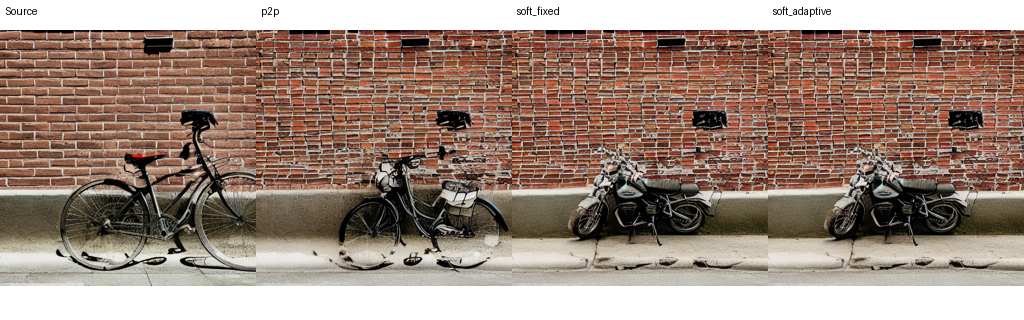

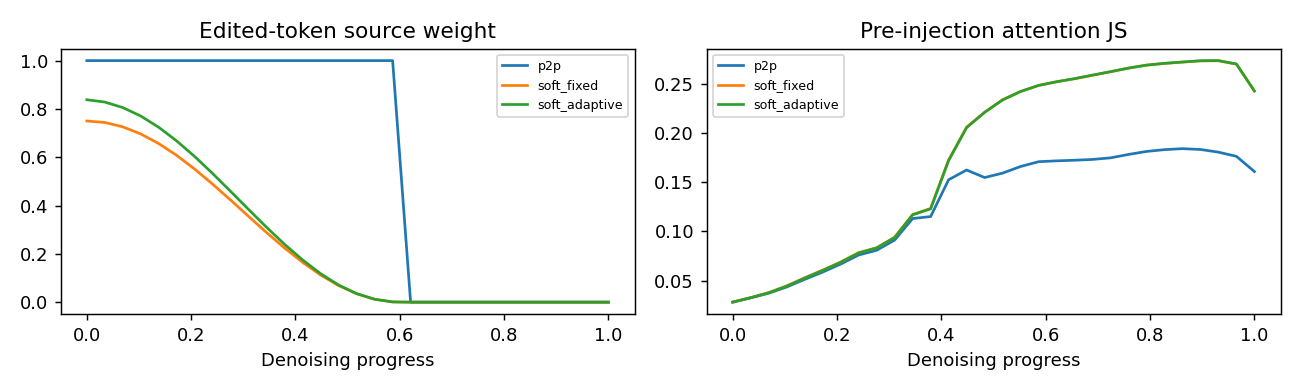

**generated_5**

a photo of a sitting dog in a grassy park → a photo of a standing dog in a grassy park

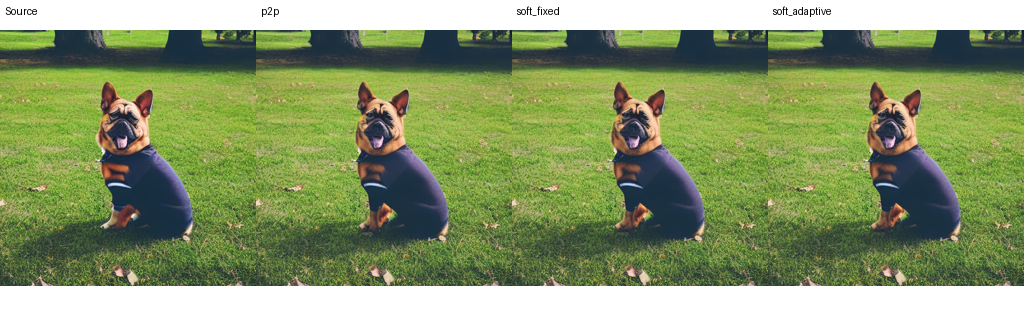

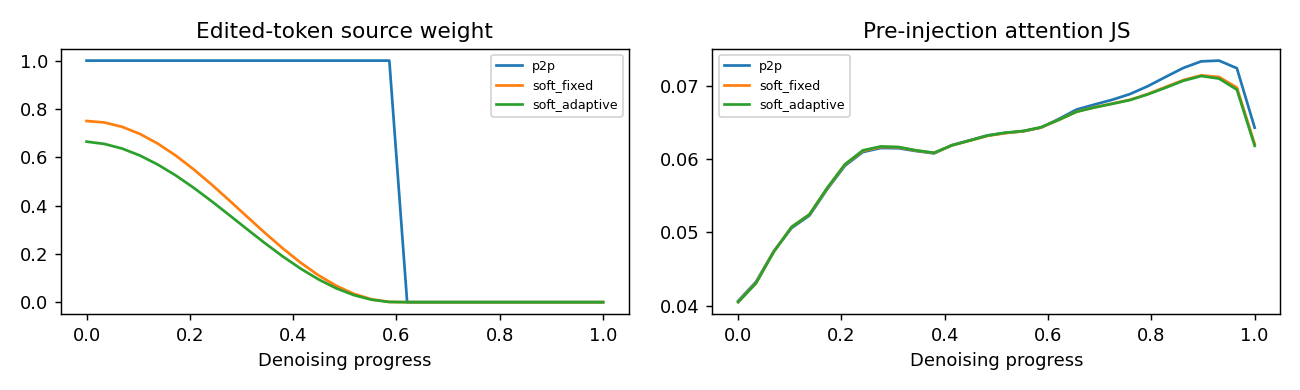

**generated_6**

a photo of a red car parked on a street → a photo of a blue car parked on a street

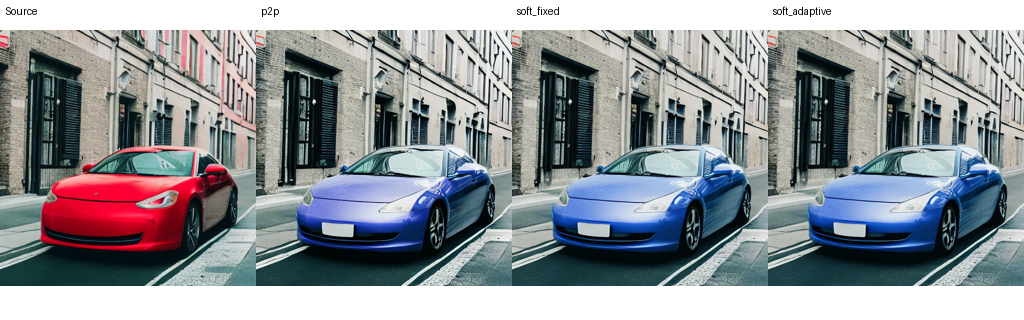

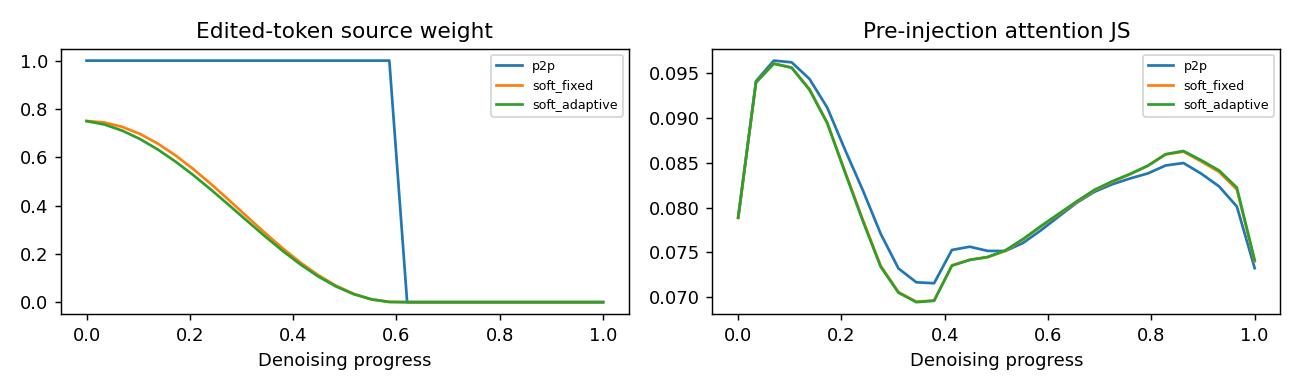

**generated_7**

a photo of a wooden bowl on a table → a photo of a glass bowl on a table

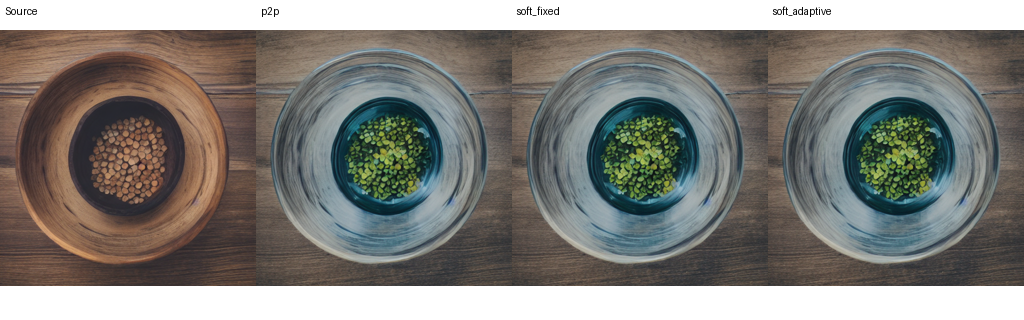

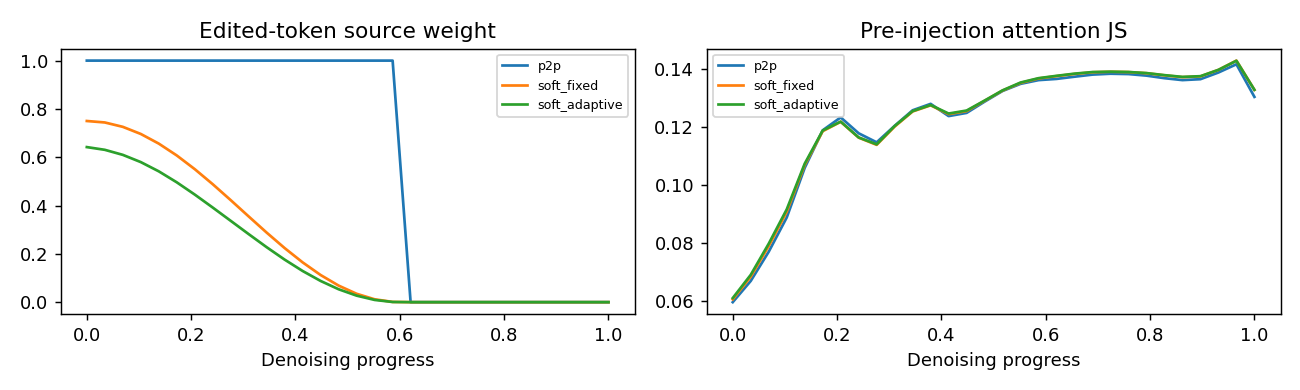

In [9]:
for folder in sorted((OUTPUT_DIR / "qualitative").glob("*")):
    prompts = json.loads((folder / "prompts.json").read_text())
    display(Markdown(f"**{folder.name}**\n\n{prompts['source_prompt']} → {prompts['target_prompt']}"))
    display(DisplayImage(filename=str(folder / "comparison.png")))
    display(DisplayImage(filename=str(folder / "weights.png")))

## 9. 保存运行验收状态与导出

T4验收包含：至少一张生成图（有真实数据时也至少一张真实图）的三方法运行完成、
文件可读、source branch跨方法一致、指标覆盖。真正的效果需要阅读指标和图像；
随机网络CPU测试通过不能替代这一步。没有真实数据时明确标注 real_smoke=false。

In [10]:
import numpy as np
from PIL import Image
from evaluate_adaptive_p2p import valid_result
manifest = json.loads((OUTPUT_DIR / "manifest.json").read_text())
registry = json.loads((OUTPUT_DIR / "registry.json").read_text())["records"]
passed = {"generated": [], "real": []}
for sample in manifest["samples"]:
    if sample["split"] == "dev":
        continue
    runs = [r["result"] for r in registry if r["sample_id"] == sample["id"]]
    if {r["method"] for r in runs} != {"p2p", "soft_fixed", "soft_adaptive"}:
        continue
    assert all(valid_result(r) for r in runs)
    sources = [np.asarray(Image.open(r["source_branch_path"])).astype(int) for r in runs]
    assert all(np.abs(x - sources[0]).max() <= 1 for x in sources)
    passed[sample["kind"]].append(sample["id"])
validation = {"gpu": torch.cuda.get_device_name(0),
              "generated_smoke": bool(passed["generated"]), "real_smoke": bool(passed["real"]),
              "complete_sample_ids": passed, "metrics_report_exists": (OUTPUT_DIR / "summary.csv").exists(),
              "note": "Runtime integrity only; see coverage and paired metrics for actual effectiveness."}
save_json(OUTPUT_DIR / "colab_validation.json", validation)
print(validation)
# report用于分享；checkpoint包含初始latent，用于恢复到相同的远端绝对路径。
# 不包含模型缓存或 PIE-Bench 原始数据；更换服务器后需另行准备它们。
import zipfile
for kind in ("report", "checkpoint"):
    export_path = OUTPUT_DIR.parent / (OUTPUT_DIR.name + "_" + kind + ".zip")
    with zipfile.ZipFile(export_path, "w", zipfile.ZIP_DEFLATED) as archive:
        for path in OUTPUT_DIR.rglob("*"):
            if path.is_file() and (kind == "checkpoint" or path.suffix != ".pt"):
                archive.write(path, path.relative_to(OUTPUT_DIR.parent))
    print(kind, "remote path:", export_path)
print("从 VS Code 的 Colab Contents 获取上述ZIP，或保留在已挂载Drive。保存notebook本身不会下载结果文件。")

{'gpu': 'Tesla T4', 'generated_smoke': True, 'real_smoke': False, 'complete_sample_ids': {'generated': ['generated_6', 'generated_7', 'generated_1', 'generated_5'], 'real': []}, 'metrics_report_exists': True, 'note': 'Runtime integrity only; see coverage and paired metrics for actual effectiveness.'}
report remote path: /content/drive/MyDrive/p2p_research/synthetic_vscode_v1_report.zip
checkpoint remote path: /content/drive/MyDrive/p2p_research/synthetic_vscode_v1_checkpoint.zip
从 VS Code 的 Colab Contents 获取上述ZIP，或保留在已挂载Drive。保存notebook本身不会下载结果文件。
